# 💳 Credit Card Fraud Detection



## 1. Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

## 2. Load the data

**Dataset:** [Credit Card Fraud Detection (Kaggle, ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) —
284,807 transactions made by European cardholders over two days in September 2013, of which 492 are frauds.

| Column | Meaning |
|---|---|
| `V1`–`V28` | Anonymised features (PCA components of the original confidential data) |
| `Time` | Seconds elapsed since the first transaction in the dataset |
| `Amount` | Transaction amount |
| `Class` | Target: 1 = fraud, 0 = normal |

The cell below downloads the file with `kagglehub`. If that fails, it asks you to upload `creditcard.csv`.

In [ ]:
DATA_FILE = "creditcard.csv"

if not os.path.exists(DATA_FILE):
    try:
        import kagglehub
        dataset_path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
        DATA_FILE = os.path.join(dataset_path, "creditcard.csv")
    except Exception as exc:
        print("Automatic download failed:", exc)
        print("Please upload creditcard.csv downloaded from Kaggle.")
        from google.colab import files
        files.upload()

df = pd.read_csv(DATA_FILE)
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Exploratory data analysis

In [ ]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

class_counts = df["Class"].value_counts().sort_index()
print("\nClass counts:")
print(class_counts.rename({0: "Normal", 1: "Fraud"}))
fraud_rate = class_counts[1] / len(df)
print(f"\nFraud rate: {fraud_rate:.4%}")
print(f"A model that ALWAYS predicts 'normal' would score {1 - fraud_rate:.2%} accuracy "
      "while catching zero frauds -> accuracy is the wrong metric here.")

Missing values: 0
Duplicate rows: 1081

Class counts:
Class
Normal    284315
Fraud        492
Name: count, dtype: int64

Fraud rate: 0.1727%
A model that ALWAYS predicts 'normal' would score 99.83% accuracy while catching zero frauds -> accuracy is the wrong metric here.


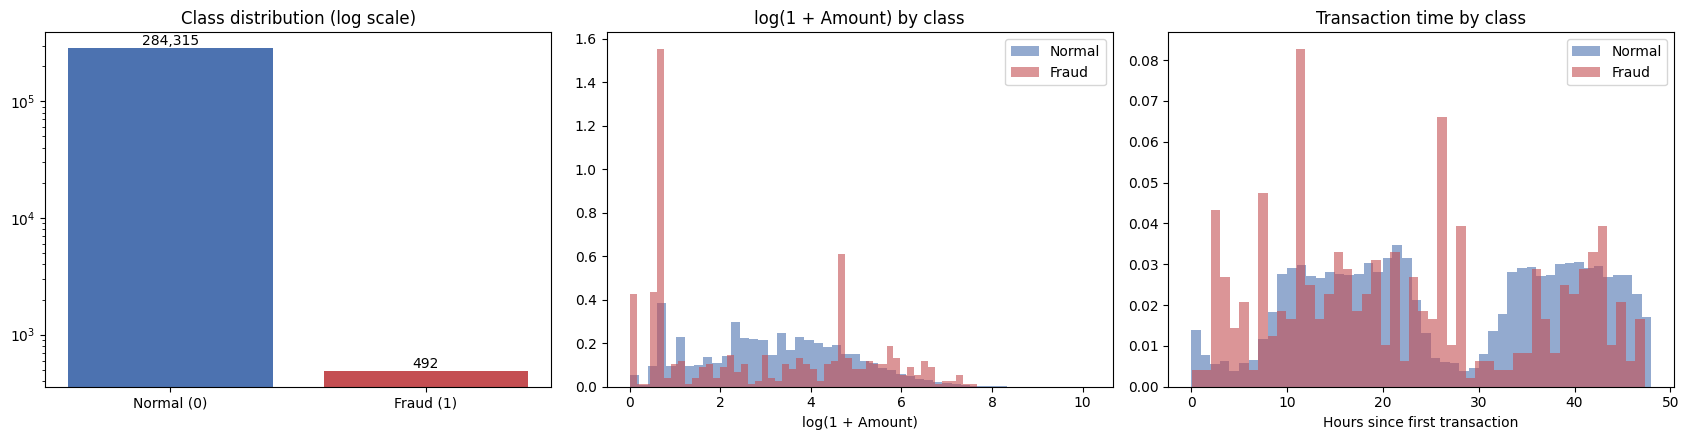

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].bar(["Normal (0)", "Fraud (1)"], class_counts.values, color=["#4C72B0", "#C44E52"])
axes[0].set_yscale("log")
axes[0].set_title("Class distribution (log scale)")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

for label, color, name in [(0, "#4C72B0", "Normal"), (1, "#C44E52", "Fraud")]:
    subset = df[df["Class"] == label]
    axes[1].hist(np.log1p(subset["Amount"]), bins=50, density=True, alpha=0.6, color=color, label=name)
    axes[2].hist(subset["Time"] / 3600, bins=48, density=True, alpha=0.6, color=color, label=name)

axes[1].set_title("log(1 + Amount) by class")
axes[1].set_xlabel("log(1 + Amount)")
axes[1].legend()
axes[2].set_title("Transaction time by class")
axes[2].set_xlabel("Hours since first transaction")
axes[2].legend()

plt.tight_layout()
plt.savefig("figures/eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

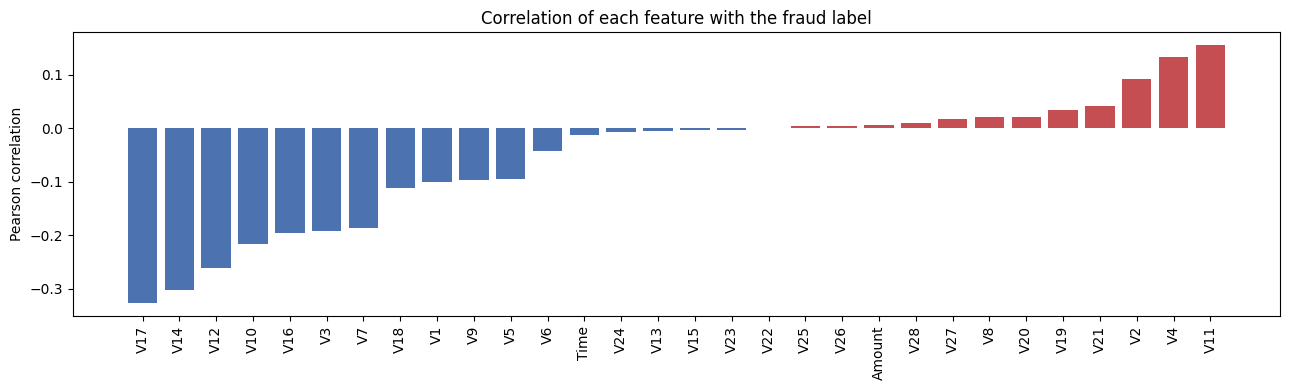

In [ ]:
correlations = df.drop(columns="Class").corrwith(df["Class"]).sort_values()

plt.figure(figsize=(13, 4))
plt.bar(correlations.index, correlations.values,
        color=np.where(correlations.values > 0, "#C44E52", "#4C72B0"))
plt.xticks(rotation=90)
plt.title("Correlation of each feature with the fraud label")
plt.ylabel("Pearson correlation")
plt.tight_layout()
plt.savefig("figures/feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

**EDA findings → preprocessing decisions**

- **Extreme class imbalance** (≈1 fraud per 580 transactions) → use **class weights**, a **stratified** split,
  and judge models by **PR-AUC, precision, recall and F1**, not accuracy.
- **`Amount` is highly skewed** → apply `log(1 + Amount)` before scaling.
- **`Time`** only counts seconds from the start of a 2-day window, so it would not generalise to new data → **dropped**.
- **Duplicate rows** exist → removed **before** splitting so the same transaction cannot appear in both train and test (data leakage).
- No missing values. Several PCA features (e.g. `V14`, `V17`, `V12`) are strongly related to fraud.

## 4. Preprocessing and splits

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler

# ---------- 1. Clean (df was already loaded in section 2) ----------
print("Duplicates removed:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(df["Class"].value_counts())

# ---------- 2. Feature engineering ----------
# Time is only seconds since the first transaction -> drop it
# Amount is heavily right-skewed -> log transform
df["Amount_log"] = np.log1p(df["Amount"])
df = df.drop(columns=["Time", "Amount"])

# ---------- 3. Split: 60% train / 20% validation / 20% test (all stratified) ----------
X = df.drop(columns="Class")
y = df["Class"]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_train_full, X_val, y_train_full, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)

# ---------- 4. Scale (fit on NORMAL training rows only) ----------
v_cols = [f"V{i}" for i in range(1, 29)]
amt_cols = ["Amount_log"]
X_train_normal = X_train_full[y_train_full == 0]

v_scaler = StandardScaler().fit(X_train_normal[v_cols])
amt_scaler = RobustScaler().fit(X_train_normal[amt_cols])

def transform(Xdf):
    Xdf = Xdf.copy()
    Xdf[v_cols] = v_scaler.transform(Xdf[v_cols])
    Xdf[amt_cols] = amt_scaler.transform(Xdf[amt_cols])
    return Xdf.values.astype("float32")

X_train_full_s = transform(X_train_full)
X_val_s = transform(X_val)
X_test_s = transform(X_test)
y_train_full = y_train_full.values
y_val = y_val.values
y_test = y_test.values

print("\nTrain:", X_train_full_s.shape, "| frauds:", y_train_full.sum())
print("Val  :", X_val_s.shape, "| frauds:", y_val.sum())
print("Test :", X_test_s.shape, "| frauds:", y_test.sum())

Duplicates removed: 1081
Class
0    283253
1       473
Name: count, dtype: int64

Train: (170235, 29) | frauds: 284
Val  : (56745, 29) | frauds: 94
Test : (56746, 29) | frauds: 95


## 5. Autoencoder (unsupervised anomaly detection)

An autoencoder compresses each transaction into a small code and tries to rebuild it.
We train it **only on normal transactions**, so it gets good at rebuilding normal behaviour.
A fraud looks different, is rebuilt badly, and gets a **high reconstruction error**, which we use as the fraud score.

The autoencoder never sees a fraud label while learning, which makes it useful when labels are rare or arrive late.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

# Split the NORMAL training rows into two parts:
#   80% -> the autoencoder learns from these
#   20% -> never seen by the autoencoder; used later to train the XGBoost classifier
#          (so the classifier sees realistic, un-memorised reconstruction errors)
normal_idx = np.where(y_train_full == 0)[0]
fraud_idx = np.where(y_train_full == 1)[0]
np.random.RandomState(42).shuffle(normal_idx)
n_fit = int(0.8 * len(normal_idx))
ae_fit_idx, ae_hold_idx = normal_idx[:n_fit], normal_idx[n_fit:]

X_ae_train = X_train_full_s[ae_fit_idx]
X_val_normal = X_val_s[y_val == 0]          # only used for early stopping
print("Autoencoder trains on", X_ae_train.shape[0], "normal transactions (no frauds)")

Autoencoder trains on 135960 normal transactions (no frauds)


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │           720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 29)             │           725 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,533 (9.89 KB)

 Trainable params: 2,533 (9.89 KB)

 Non-trainable params: 0 (0.00 B)

Stopped after 100 epochs | best validation MSE: 0.2640


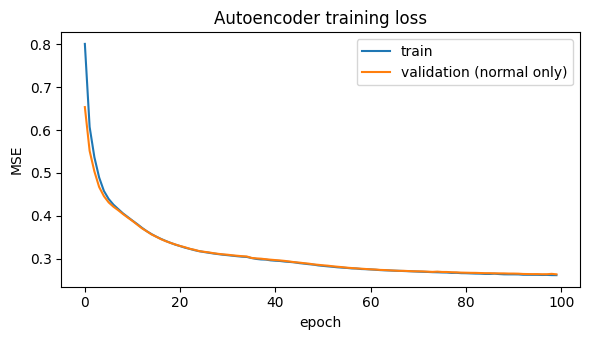

In [ ]:
input_dim = X_ae_train.shape[1]

inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(24, activation="relu")(inputs)
x = layers.Dense(16, activation="relu")(x)
latent = layers.Dense(8, activation="relu", name="latent")(x)      # bottleneck
x = layers.Dense(16, activation="relu")(latent)
x = layers.Dense(24, activation="relu")(x)
outputs = layers.Dense(input_dim, activation="linear")(x)

autoencoder = keras.Model(inputs, outputs, name="autoencoder")
autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
autoencoder.summary()

history = autoencoder.fit(
    X_ae_train, X_ae_train,
    validation_data=(X_val_normal, X_val_normal),
    epochs=100, batch_size=256, verbose=0,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
    ],
)

print(f"Stopped after {len(history.history['loss'])} epochs | best validation MSE: {min(history.history['val_loss']):.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation (normal only)")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Autoencoder training loss"); plt.legend()
plt.tight_layout()
plt.savefig("figures/ae_training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Evaluation

**Why not accuracy?** Predicting "normal" every time scores 99.83% accuracy and catches nothing. We use:

- **PR-AUC (average precision)**: the main metric. It focuses on the rare fraud class and ignores the huge pile of true negatives.
- **Precision**: of the transactions we flag, how many are real fraud (false alarms cost customer trust).
- **Recall**: of all frauds, how many we catch (misses cost money).
- **F1 / MCC**: single numbers that balance precision and recall. MCC stays honest under heavy imbalance.
- **ROC-AUC**: reported for reference, but it looks flattering on imbalanced data.

The decision threshold is chosen on the **validation** set (best F1) and then applied once to the **test** set, so the test numbers are not tuned.

In [ ]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix)

results = {}       # metrics table
test_scores = {}   # raw test scores, used for the PR curves

def best_f1_threshold(y_true, scores):
    """Pick the score threshold that maximises F1 on the VALIDATION set."""
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return t[np.argmax(f1)]

def evaluate(name, s_val, s_test):
    """s_val / s_test = anomaly or fraud scores (higher = more suspicious)."""
    thr = best_f1_threshold(y_val, s_val)          # threshold chosen WITHOUT touching test
    pred = (s_test >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    results[name] = {
        "PR-AUC": average_precision_score(y_test, s_test),
        "ROC-AUC": roc_auc_score(y_test, s_test),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "MCC": matthews_corrcoef(y_test, pred),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }
    test_scores[name] = s_test
    print(f"{name}\n" + "-" * len(name))
    for k in ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "MCC"]:
        print(f"  {k:<10}: {results[name][k]:.4f}")
    print(f"  Caught {tp} of {tp + fn} frauds, with {fp} false alarms out of {tn + fp:,} normal transactions\n")

Autoencoder (unsupervised)
--------------------------
  PR-AUC    : 0.5794
  ROC-AUC   : 0.9442
  Precision : 0.6804
  Recall    : 0.6947
  F1        : 0.6875
  MCC       : 0.6870
  Caught 66 of 95 frauds, with 31 false alarms out of 56,651 normal transactions



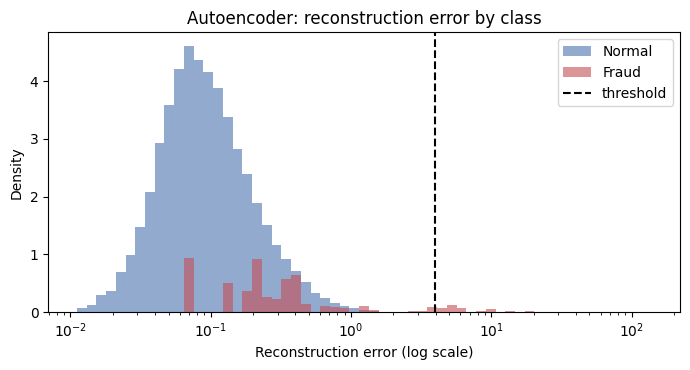

In [ ]:
def recon_error(X):
    """Mean squared reconstruction error per transaction = anomaly score."""
    recon = autoencoder.predict(X, batch_size=4096, verbose=0)
    return np.mean((X - recon) ** 2, axis=1)

val_err, test_err = recon_error(X_val_s), recon_error(X_test_s)
evaluate("Autoencoder (unsupervised)", val_err, test_err)

# How well does the reconstruction error separate the two classes?
bins = np.logspace(np.log10(max(test_err.min(), 1e-4)), np.log10(test_err.max()), 60)
plt.figure(figsize=(7, 3.8))
plt.hist(test_err[y_test == 0], bins=bins, density=True, alpha=0.6, color="#4C72B0", label="Normal")
plt.hist(test_err[y_test == 1], bins=bins, density=True, alpha=0.6, color="#C44E52", label="Fraud")
plt.axvline(best_f1_threshold(y_val, val_err), color="k", ls="--", label="threshold")
plt.xscale("log"); plt.xlabel("Reconstruction error (log scale)"); plt.ylabel("Density")
plt.title("Autoencoder: reconstruction error by class"); plt.legend()
plt.tight_layout()
plt.savefig("figures/ae_error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Supervised model: XGBoost

A purely unsupervised autoencoder never uses the 473 labelled frauds, so it has a ceiling.
Here we train **XGBoost** on the raw features using the labels.
The classifier is trained on normal rows the autoencoder did not use, plus all training frauds.


In [ ]:
# Classifier training rows: normals held out from the autoencoder + ALL training frauds
clf_idx = np.concatenate([ae_hold_idx, fraud_idx])
X_clf, y_clf = X_train_full_s[clf_idx], y_train_full[clf_idx]

print("Classifier training rows:", X_clf.shape[0], "| frauds:", int(y_clf.sum()))
print("Feature count:", X_clf.shape[1])


Classifier training rows: 34275 | frauds: 284
Feature count: 29


In [ ]:
from xgboost import XGBClassifier

def train_xgb(X_tr, y_tr, X_v, y_v):
    # scale_pos_weight handles the class imbalance (weights each fraud ~ #normal / #fraud)
    model = XGBClassifier(
        n_estimators=1000, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
        eval_metric="aucpr", early_stopping_rounds=50,
        tree_method="hist", random_state=42, n_jobs=-1)
    model.fit(X_tr, y_tr, eval_set=[(X_v, y_v)], verbose=False)
    return model

xgb_raw = train_xgb(X_clf, y_clf, X_val_s, y_val)
evaluate("XGBoost (raw features)",
         xgb_raw.predict_proba(X_val_s)[:, 1], xgb_raw.predict_proba(X_test_s)[:, 1])


XGBoost (raw features)
----------------------
  PR-AUC    : 0.8124
  ROC-AUC   : 0.9656
  Precision : 0.9189
  Recall    : 0.7158
  F1        : 0.8047
  MCC       : 0.8107
  Caught 68 of 95 frauds, with 6 false alarms out of 56,651 normal transactions



## 8. Model comparison

,PR-AUC,ROC-AUC,Precision,Recall,F1,MCC
Autoencoder (unsupervised),0.5794,0.9442,0.6804,0.6947,0.6875,0.6870
XGBoost (raw features),0.8124,0.9656,0.9189,0.7158,0.8047,0.8107


,TP,FP,FN,TN
Autoencoder (unsupervised),66,31,29,56620
XGBoost (raw features),68,6,27,56645


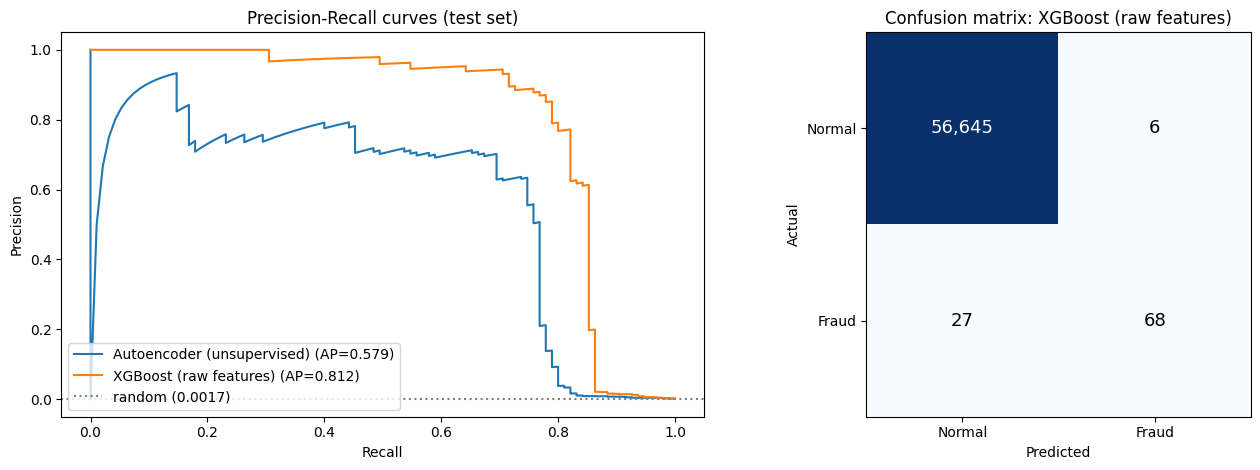

In [ ]:
summary = pd.DataFrame(results).T
display(summary[["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "MCC"]].round(4))
display(summary[["TP", "FP", "FN", "TN"]].astype(int))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Precision-Recall curves (the key plot for imbalanced data)
for name, s in test_scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    axes[0].plot(r, p, label=f"{name} (AP={results[name]['PR-AUC']:.3f})")
axes[0].axhline(y_test.mean(), color="gray", ls=":", label=f"random ({y_test.mean():.4f})")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves (test set)")
axes[0].legend(loc="lower left")

# Confusion matrix of the best model by PR-AUC
best = summary["PR-AUC"].idxmax()
cm = np.array([[summary.loc[best, "TN"], summary.loc[best, "FP"]],
               [summary.loc[best, "FN"], summary.loc[best, "TP"]]]).astype(int)
axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black", fontsize=13)
axes[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Normal", "Fraud"],
            yticklabels=["Normal", "Fraud"], xlabel="Predicted", ylabel="Actual",
            title=f"Confusion matrix: {best}")
plt.tight_layout()
plt.savefig("figures/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Results description**

Both models were evaluated on the same held-out test set (56,746 transactions, 95 of them fraud), using a threshold chosen on the validation set.

| Model | PR-AUC | ROC-AUC | Precision | Recall | F1 | MCC | Frauds caught | False alarms |
|---|---|---|---|---|---|---|---|---|
| Autoencoder (unsupervised) | 0.579 | 0.944 | 0.680 | 0.695 | 0.688 | 0.687 | 66 of 95 | 31 |
| XGBoost (raw features) | 0.812 | 0.966 | 0.919 | 0.716 | 0.805 | 0.811 | 68 of 95 | 6 |

- **Autoencoder:** Trained only on normal transactions and never shown a fraud label, it still caught 66 of the 95 frauds (recall 0.69) with 31 false alarms (precision 0.68). Its ROC-AUC of 0.944 shows that reconstruction error separates fraud from normal transactions well, but its PR-AUC of 0.579 shows that the ranking is much less clean on the rare fraud class.
- **XGBoost:** Using the fraud labels, it caught slightly more frauds (68 of 95, recall 0.72) but with far fewer false alarms (6 versus 31), so precision rises to 0.92. It leads on every metric, with PR-AUC 0.812 against 0.579 and F1 0.805 against 0.688.
- **Comparison:** The two models catch a similar number of frauds. The main difference is precision: XGBoost raises roughly five times fewer false alarms. XGBoost is the best model and is the one shown in the confusion matrix.
- **Trade-off:** The autoencoder needs no labels, so it suits cases where labels are rare or late, and it can flag new kinds of fraud. XGBoost needs labelled frauds but is clearly more accurate when they are available.
- **Caution:** The test set has only 95 frauds, so a few catches more or fewer shift recall and precision noticeably. Treat small differences with care, though the precision gap between the two models is large enough to be reliable.
